In [1]:
from lights.plotting import setup_style
from lights.constants import mB
from lights.load_data import BelleII, BaBar
from lights.signal_rates import s_SM_BelleII, s_SM_BaBar
from lights.likelihoods import min_logLL, profile_logLL_SM, components_BelleII
from lights.statistics import reduced_chisq

import numpy as np
import matplotlib.pyplot as plt

setup_style()

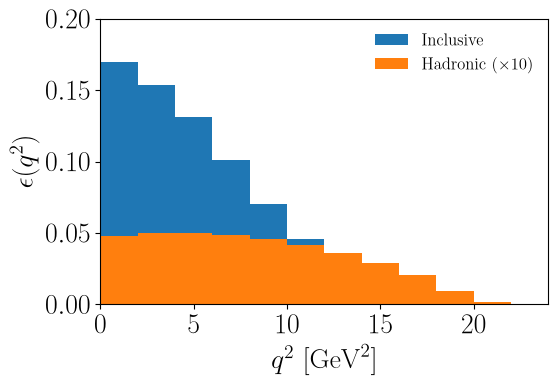

In [2]:
fig, axes = plt.subplots(nrows=1, ncols=1)

tot1 = axes.stairs(BelleII.eff_vals, BelleII.eff_bins, fill=True)
tot2 = axes.stairs(10*BelleII.effHad_vals, BelleII.eff_bins, fill=True)

axes.set_xlim(0,24);
axes.set_ylim(0,0.20);
axes.set_xlabel(r'$q^2~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$\epsilon(q^2)$');

leg1 = axes.legend([tot1, tot2], [r'Inclusive', r'Hadronic ($\times 10$)'], loc='upper right', fontsize=12, frameon=False)

plt.subplots_adjust(left=0.2)
plt.subplots_adjust(bottom=0.2)
fig.set_size_inches(6.4, 4.2)

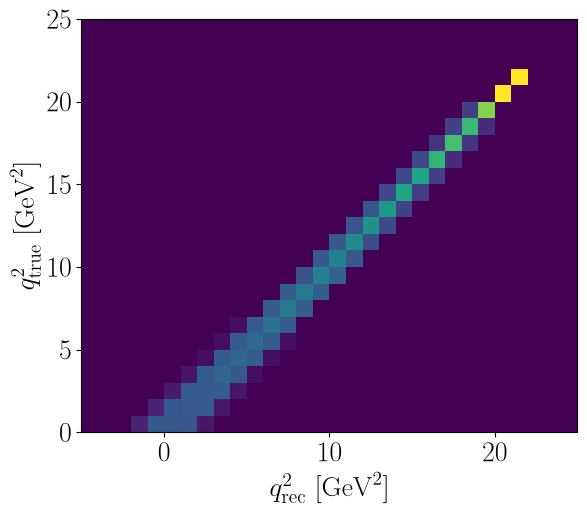

In [3]:
fig, axes = plt.subplots(nrows=1, ncols=1)

axes.imshow(BelleII.smearing_data, extent = (-5, 25, 25, -5));

axes.set_xlim(-5,25);
axes.set_ylim(0,25);
axes.set_xlabel(r'$q^2_{\mathrm{rec}}~[\mathrm{GeV}^2]$');
axes.set_ylabel(r'$q^2_{\mathrm{true}}~[\mathrm{GeV}^2]$');

fig.set_size_inches(6.4, 9.6)

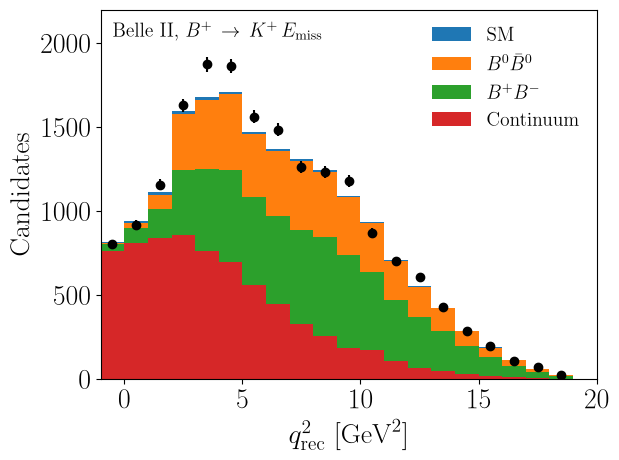

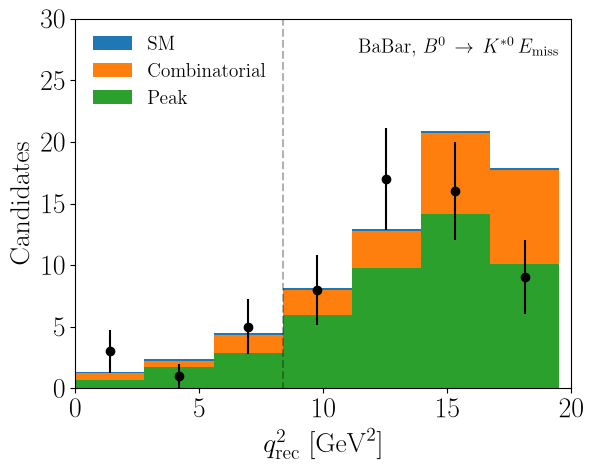

In [4]:
def plot_stack(layers, edges, centres, data, xlim, ylim, text_xy, text, legend_loc=None, guide=None):
    "Stacked histogram of the labelled layers (bottom layer first) with the observed counts."
    fig, axes = plt.subplots(nrows=1, ncols=1)
    totals = np.cumsum(list(layers.values()), axis=0)[::-1]     # top of the stack first
    handles = [axes.stairs(total, edges, fill=True) for total in totals]
    if guide is not None:                                       # dashed vertical line at x = guide
        axes.plot([guide, guide], [-1, 1.1 * ylim[1]], color='k', ls='--', alpha=0.3)
    axes.errorbar(centres, data, fmt='ok', yerr=np.sqrt(data))
    axes.set_xlim(*xlim)
    axes.set_ylim(*ylim)
    axes.set_xlabel(r'$q^2_{\mathrm{rec}}~[\mathrm{GeV}^2]$')
    axes.set_ylabel(r'$\mathrm{Candidates}$')
    if legend_loc is not None:
        axes.legend(handles, list(layers)[::-1], loc=legend_loc, fontsize=14, frameon=False)
    axes.text(*text_xy, text, fontsize=14)
    fig.set_size_inches(6.4, 4.8)
    return fig, axes

BELLE_LABELS = [r'Continuum', r'$B^+B^-$', r'$B^0\bar{B}^0$', r'SM']
BELLE_TEXT = r'Belle~II,~$B^+\,\to \,K^+\,E_{\mathrm{miss}}%s$'

plot_stack(dict(zip(BELLE_LABELS, [BelleII.b_cont, BelleII.b_charged, BelleII.b_neutral, s_SM_BelleII])),
           BelleII.bins, BelleII.bin_cents, BelleII.obs,
           xlim=(-1, 20), ylim=(0, 2200), text_xy=(-0.5, 2040), text=BELLE_TEXT % '', legend_loc='upper right')

plot_stack({r'Peak': BaBar.b_peak, r'Combinatorial': BaBar.b_comb, r'SM': s_SM_BaBar},
           BaBar.bins, BaBar.bin_cents, BaBar.obs, xlim=(0, 20), ylim=(0, 30),
           text_xy=(11.4, 27.25), text=r'BaBar,~$B^0\,\to \,K^{*0} \, E_{\mathrm{miss}}$', legend_loc='upper left',
           guide=0.3 * mB**2);

In [5]:
mu_val, mu_err, m_BelleII, mu_min = min_logLL("BelleII")
mu_val, mu_err, mu_min

(5.0854922865275745, 1.587093026283267, -6.693135894951411)

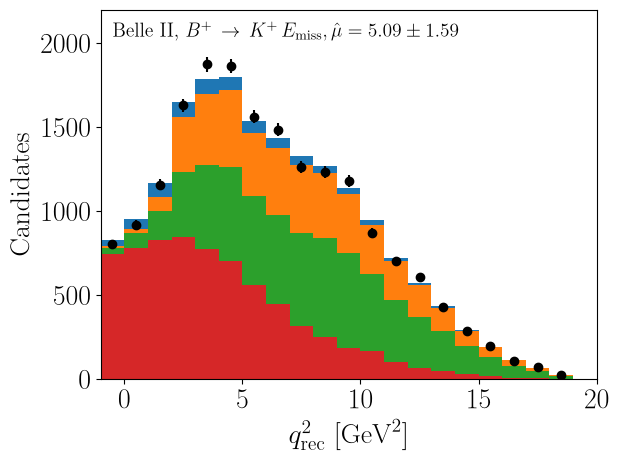

In [6]:
# Fitted signal and background components per bin (includes the fitted nuisance parameters)
comp = components_BelleII(m_BelleII.values)

plot_stack(dict(zip(BELLE_LABELS, [comp["cont"], comp["charged"], comp["neutral"], comp["SM"]])),
           BelleII.bins, BelleII.bin_cents, BelleII.obs,
           xlim=(-1, 20), ylim=(0, 2200), text_xy=(-0.5, 2040),
           text=BELLE_TEXT % (r', \hat{\mu} = %1.2f \pm %1.2f ' % (mu_val, mu_err)));

In [7]:
chisq_inc = reduced_chisq(m_BelleII, BelleII.obs)
print(chisq_inc)

1.9806174009404218


In [8]:
mu_scan = np.linspace(0., 8, 50)
profile = profile_logLL_SM("BelleII", mu_scan)

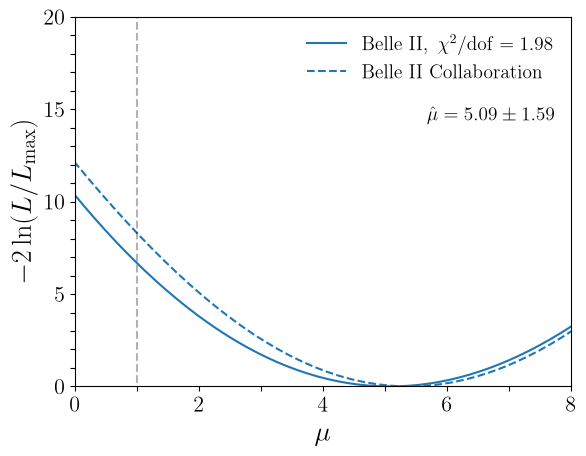

In [9]:
# Compare log likelihoods
fig, axes = plt.subplots(nrows=1, ncols=1)

tot1, = axes.plot(mu_scan, profile, color='C0', ls='-')
tot2, = axes.plot(BelleII.ita_profile[:, 0], BelleII.ita_profile[:, 1], color='C0', ls='--')

axes.plot([1,1],[-1,81],color='k',ls='--',alpha=0.3)

axes.set_xticks(range(9), [rf'${i}$' if i % 2 == 0 else '' for i in range(9)], fontsize=16)
axes.set_yticks(range(21), [rf'${i}$' if i % 5 == 0 else '' for i in range(21)], fontsize=16)

axes.set_xlim(0,8)
axes.set_ylim(0,20)
axes.set_xlabel(r'$\mu$');
axes.set_ylabel(r'$-2\ln(L/L_\mathrm{max})$');

axes.text(5.68, 14.4, r'$\hat{\mu} = %1.2f \pm %1.2f $' % (mu_val, mu_err), fontsize=14)

leg1 = axes.legend([tot1,tot2], [r'Belle II, $\,\chi^2/\mathrm{dof} = %1.2f$ ' % chisq_inc, r'Belle II Collaboration'], loc='upper right', fontsize=14, frameon=False)

fig.set_size_inches(6.4, 4.8)